In [7]:
import os
import json
import shutil
import subprocess
import time
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Téléchargement automatique du Grocery Store Dataset dans /tmp (déjà en cache)
repo_dir = "/tmp/GroceryStoreDataset"
if not os.path.exists(repo_dir):
    print("Téléchargement du dataset en cours...")
    subprocess.run(
        ["git", "clone", "--depth", "1", "https://github.com/marcusklasson/GroceryStoreDataset.git", repo_dir],
        check=True
    )

TRAIN_RAW = os.path.join(repo_dir, "dataset", "train")
VAL_RAW = os.path.join(repo_dir, "dataset", "val")

# 2. Regroupement des 81 classes de produits
def preparer_dossiers_classes(src_dir, dst_dir):
    if os.path.exists(dst_dir):
        shutil.rmtree(dst_dir)
    os.makedirs(dst_dir, exist_ok=True)
    extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
    for root, _, files in os.walk(src_dir):
        if any(f.lower().endswith(extensions) for f in files):
            classe = os.path.basename(root)
            cible = os.path.join(dst_dir, classe)
            if not os.path.exists(cible):
                shutil.copytree(root, cible)
    return dst_dir

TRAIN_DIR = preparer_dossiers_classes(TRAIN_RAW, "/tmp/data_cnn/train")
VAL_DIR = preparer_dossiers_classes(VAL_RAW, "/tmp/data_cnn/val")

# Synchronisation des 81 classes entre train et val
for classe in os.listdir(TRAIN_DIR):
    os.makedirs(os.path.join(VAL_DIR, classe), exist_ok=True)

# 3. Chargement des images
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)
assert train_ds.class_names == val_ds.class_names, "Désalignement des classes train/val"
print(f"Nombre de classes de produits détectées : {num_classes} (Train & Val alignés)")

with open("/kaggle/working/classes_cnn.json", "w", encoding="utf-8") as f:
    json.dump(class_names, f, ensure_ascii=False, indent=2)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

Found 2640 files belonging to 81 classes.
Found 296 files belonging to 81 classes.
Nombre de classes de produits détectées : 81 (Train & Val alignés)


In [9]:
# Data Augmentation pour simuler les variations d'angle et de lumière en caisse
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="augmentation_caisse")

# --- MODÈLE 1 : CNN Simple (Baseline) ---
def construire_cnn_baseline(num_classes):
    inputs = tf.keras.Input(shape=(224, 224, 3))
    x = layers.Rescaling(1./255)(inputs)
    x = layers.Conv2D(32, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, activation="relu", padding="same")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return models.Model(inputs, outputs, name="CNN_Baseline")

baseline_model = construire_cnn_baseline(num_classes)
baseline_model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])

print("--- Entraînement CNN Baseline (8 epochs) ---")
baseline_model.fit(train_ds, validation_data=val_ds, epochs=8, verbose=1)
_, acc_base = baseline_model.evaluate(val_ds, verbose=0)

# --- MODÈLE 2 : Transfer Learning MobileNetV2 ---
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.4)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs, name="SmartRetail_MobileNetV2")
loss_fn = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=loss_fn,
    metrics=["accuracy"]
)

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True
)

print("\n--- Entraînement MobileNetV2 (15 epochs max) ---")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop],
    verbose=1
)

# Fine-tuning contrôlé : on dégèle les 25 dernières couches SAUF BatchNormalization
base_model.trainable = True
for layer in base_model.layers[:-25]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=2e-5),
    loss=loss_fn,
    metrics=["accuracy"]
)

print("\n--- Fine-Tuning MobileNetV2 (8 epochs max) ---")
history_ft = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[early_stop],
    verbose=1
)

_, acc_mobilenet = model.evaluate(val_ds, verbose=0)
print(f"\nRÉSULTAT COMPARATIF -> CNN Baseline: {acc_base*100:.2f}% | MobileNetV2: {acc_mobilenet*100:.2f}%")

# Sauvegarde du modèle entraîné
model.save("/kaggle/working/cnn_smart_retail.keras")

--- Entraînement CNN Baseline (8 epochs) ---
Epoch 1/8
83/83 ━━━━━━━━━━━━━━━━━━━━ 10s 86ms/step - accuracy: 0.0458 - loss: 4.1861 - val_accuracy: 0.0439 - val_loss: 3.9803
Epoch 2/8
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.0894 - loss: 3.6066 - val_accuracy: 0.0574 - val_loss: 3.5766
Epoch 3/8
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.1133 - loss: 3.3399 - val_accuracy: 0.0845 - val_loss: 3.4102
Epoch 4/8
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.1439 - loss: 3.1553 - val_accuracy: 0.1115 - val_loss: 3.4473
Epoch 5/8
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.1663 - loss: 2.9872 - val_accuracy: 0.1385 - val_loss: 3.0475
Epoch 6/8
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 59ms/step - accuracy: 0.1973 - loss: 2.8205 - val_accuracy: 0.1284 - val_loss: 3.1652
Epoch 7/8
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 57ms/step - accuracy: 0.2027 - loss: 2.7045 - val_accuracy: 0.1622 - val_loss: 3.0866
Epoch 8/8
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 55ms/step - accuracy: 0.2583 - l

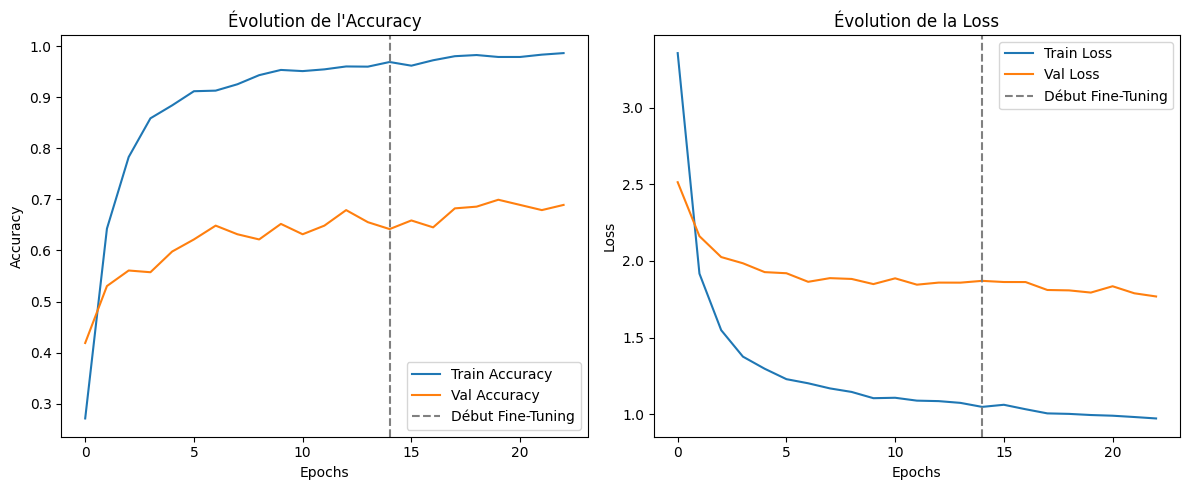

10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 167ms/step
F1-Score (Macro) : 0.5814
Temps moyen d'inférence par image : 8.75 ms

--- Rapport de Classification ---
                                        precision    recall  f1-score   support

              Alpro-Blueberry-Soyghurt       1.00      0.20      0.33         5
                  Alpro-Fresh-Soy-Milk       0.00      0.00      0.00         0
                  Alpro-Shelf-Soy-Milk       0.00      0.00      0.00         0
                Alpro-Vanilla-Soyghurt       0.50      0.40      0.44         5
                                 Anjou       0.00      0.00      0.00         0
       Arla-Ecological-Medium-Fat-Milk       0.83      1.00      0.91         5
            Arla-Ecological-Sour-Cream       0.00      0.00      0.00         0
          Arla-Lactose-Medium-Fat-Milk       0.00      0.00      0.00         0
                  Arla-Medium-Fat-Milk       0.67      0.50      0.57         4
             Arla-Mild-Vanilla-Yoghurt       0.00    

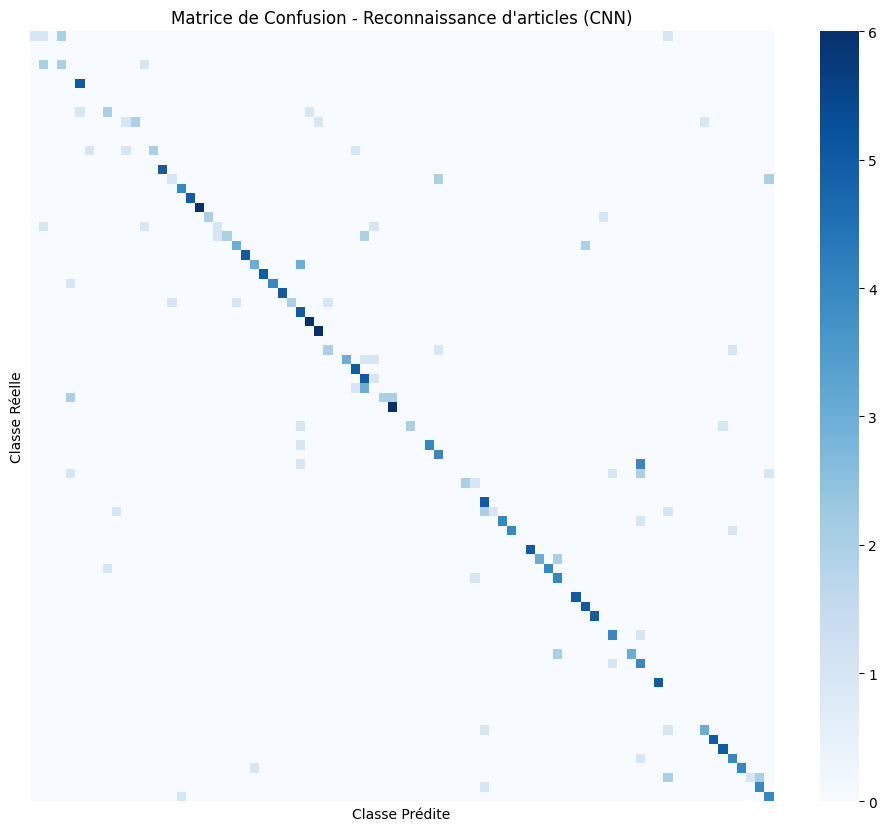

In [10]:
# 1. Courbes d'apprentissage (Accuracy & Loss)
acc = history.history["accuracy"] + history_ft.history["accuracy"]
val_acc = history.history["val_accuracy"] + history_ft.history["val_accuracy"]
loss = history.history["loss"] + history_ft.history["loss"]
val_loss = history.history["val_loss"] + history_ft.history["val_loss"]

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(acc, label="Train Accuracy")
plt.plot(val_acc, label="Val Accuracy")
plt.axvline(x=len(history.history["accuracy"])-1, color="gray", linestyle="--", label="Début Fine-Tuning")
plt.title("Évolution de l'Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label="Train Loss")
plt.plot(val_loss, label="Val Loss")
plt.axvline(x=len(history.history["loss"])-1, color="gray", linestyle="--", label="Début Fine-Tuning")
plt.title("Évolution de la Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.savefig("/kaggle/working/courbes_apprentissage_cnn.png", dpi=300)
plt.show()

# 2. Métriques et Matrice de confusion (ajustées pour les 81 classes)
y_true = np.concatenate([y for _, y in val_ds], axis=0)
y_true_classes = np.argmax(y_true, axis=1)

t0 = time.time()
y_pred_probs = model.predict(val_ds)
temps_total = time.time() - t0
y_pred_classes = np.argmax(y_pred_probs, axis=1)

f1_macro = f1_score(y_true_classes, y_pred_classes, average="macro", zero_division=0)
print(f"F1-Score (Macro) : {f1_macro:.4f}")
print(f"Temps moyen d'inférence par image : {(temps_total / len(y_true_classes))*1000:.2f} ms")
print("\n--- Rapport de Classification ---")
print(classification_report(y_true_classes, y_pred_classes, labels=np.arange(num_classes), target_names=class_names, zero_division=0))

cm = confusion_matrix(y_true_classes, y_pred_classes, labels=np.arange(num_classes))
plt.figure(figsize=(12, 10))
sns.heatmap(cm, cmap="Blues", xticklabels=False, yticklabels=False)
plt.title("Matrice de Confusion - Reconnaissance d'articles (CNN)")
plt.xlabel("Classe Prédite")
plt.ylabel("Classe Réelle")
plt.savefig("/kaggle/working/matrice_confusion_cnn.png", dpi=300)
plt.show()

In [11]:
def analyser_article_caisse(image_path: str, seuil_confiance: float = 0.75) -> dict:
    """
    Analyse un article déposé en caisse et retourne ses prédictions
    pour le RNN (séquence panier) et la Régression Logistique (validation finale).
    """
    img = tf.keras.utils.load_img(image_path, target_size=IMG_SIZE)
    img_array = tf.keras.utils.img_to_array(img)
    img_batch = np.expand_dims(img_array, axis=0)

    probs = model.predict(img_batch, verbose=0)[0]
    idx_max = int(np.argmax(probs))
    confiance = float(probs[idx_max])
    article_predit = class_names[idx_max]

    # 1 = anomalie optique (article inconnu, masqué ou trop ambigu)
    anomalie_optique = 1 if confiance < seuil_confiance else 0

    return {
        "article_detecte": article_predit,
        "confiance_cnn": round(confiance, 4),
        "anomalie_optique": anomalie_optique,
        "top_3": [
            (class_names[int(i)], round(float(probs[i]), 4))
            for i in np.argsort(probs)[::-1][:3]
        ]
    }

# Sélectionne automatiquement une classe non vide dans VAL_DIR pour le test
classes_non_vides = [c for c in os.listdir(VAL_DIR) if len(os.listdir(os.path.join(VAL_DIR, c))) > 0]
exemple_classe = classes_non_vides[0]
exemple_img = os.path.join(VAL_DIR, exemple_classe, os.listdir(os.path.join(VAL_DIR, exemple_classe))[0])

print("Classe réelle :", exemple_classe)
print("Sortie CNN    :", analyser_article_caisse(exemple_img))

Classe réelle : Pineapple
Sortie CNN    : {'article_detecte': 'Pineapple', 'confiance_cnn': 0.4021, 'anomalie_optique': 1, 'top_3': [('Pineapple', 0.4021), ('Red-Beet', 0.306), ('Asparagus', 0.06)]}
